In [2]:
import json
import time
from collections import Counter
from pathlib import Path

import ijson
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("../data/raw/model_build_inputs")

In [4]:
with open(RAW / "route_data.json") as f:
    route_data = json.load(f)

print("Number of routes:", len(route_data))

first_id = next(iter(route_data))
first = route_data[first_id]
print("Route ID:", first_id)
print("Route-level fields:", list(first.keys()))

first_stops = first["stops"]
first_stop_id = next(iter(first_stops))
print("Number of stops in this route:", len(first_stops))
print("One stop:", first_stop_id, first_stops[first_stop_id])

Number of routes: 6112
Route ID: RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77
Route-level fields: ['station_code', 'date_YYYY_MM_DD', 'departure_time_utc', 'executor_capacity_cm3', 'route_score', 'stops']
Number of stops in this route: 119
One stop: AD {'lat': 34.099611, 'lng': -118.283062, 'type': 'Dropoff', 'zone_id': 'P-12.3C'}


In [5]:
with open(RAW / "package_data.json") as f:
    package_data = json.load(f)

with open(RAW / "actual_sequences.json") as f:
    actual_sequences = json.load(f)

pk = package_data[first_id]
print("Stops with package data:", len(pk))
stop_with_pkgs = next(iter(pk))
print("One stop's packages:", stop_with_pkgs, pk[stop_with_pkgs])

print("Sequence structure:", list(actual_sequences[first_id].keys()))
seq = actual_sequences[first_id]["actual"]
print("First 10 in observed order:", dict(list(seq.items())[:10]))

from collections import Counter
print("Stop types in this route:", Counter(s["type"] for s in first_stops.values()))


Stops with package data: 119
One stop's packages: AD {'PackageID_9d7fdd03-f2cf-4c6f-9128-028258fc09ea': {'scan_status': 'DELIVERED', 'time_window': {'start_time_utc': nan, 'end_time_utc': nan}, 'planned_service_time_seconds': 59.3, 'dimensions': {'depth_cm': 25.4, 'height_cm': 7.6, 'width_cm': 17.8}}, 'PackageID_5541e679-b7bd-4992-b288-e862f6c84ae7': {'scan_status': 'DELIVERED', 'time_window': {'start_time_utc': '2018-07-27 16:00:00', 'end_time_utc': '2018-07-28 00:00:00'}, 'planned_service_time_seconds': 59.3, 'dimensions': {'depth_cm': 25.4, 'height_cm': 12.7, 'width_cm': 17.8}}, 'PackageID_84d0295b-1adb-4a33-a65e-f7d6247c7a07': {'scan_status': 'DELIVERED', 'time_window': {'start_time_utc': nan, 'end_time_utc': nan}, 'planned_service_time_seconds': 59.3, 'dimensions': {'depth_cm': 39.4, 'height_cm': 7.6, 'width_cm': 31.8}}}
Sequence structure: ['actual']
First 10 in observed order: {'AD': 105, 'AF': 47, 'AG': 4, 'BA': 33, 'BE': 109, 'BG': 53, 'BP': 67, 'BT': 49, 'BY': 7, 'BZ': 61}
St

In [6]:
# Stops table, with observed visit position
stops_df = (pd.DataFrame.from_dict(first_stops, orient="index")
              .rename_axis("stop_id").reset_index())
stops_df["seq_pos"] = stops_df["stop_id"].map(actual_sequences[first_id]["actual"])

# Packages table (one row per package)
rows = []
for stop_id, pkgs in pk.items():
    for pid, p in pkgs.items():
        rows.append({
            "stop_id": stop_id, "package_id": pid,
            "scan_status": p["scan_status"],
            "tw_start": p["time_window"]["start_time_utc"],
            "tw_end": p["time_window"]["end_time_utc"],
            "service_s": p["planned_service_time_seconds"],
            "depth_cm": p["dimensions"]["depth_cm"],
            "height_cm": p["dimensions"]["height_cm"],
            "width_cm": p["dimensions"]["width_cm"],
        })
pkg_df = pd.DataFrame(rows)
pkg_df["volume_cm3"] = pkg_df.depth_cm * pkg_df.height_cm * pkg_df.width_cm

# Sanity checks
print("Positions form a clean 0..n-1 sequence:",
      sorted(stops_df.seq_pos) == list(range(len(stops_df))))
print("Station position:", stops_df.loc[stops_df.type == "Station", "seq_pos"].item())
print("Packages:", len(pkg_df), "| stops with at least one package:", pkg_df.stop_id.nunique())
print(pkg_df.scan_status.value_counts())
print("Share of packages with a time window:", round(pkg_df.tw_start.notna().mean(), 3))
print("Total package volume vs vehicle capacity (cm3):",
      round(pkg_df.volume_cm3.sum()), "vs", first["executor_capacity_cm3"])

stops_df.sort_values("seq_pos").head(8)

Positions form a clean 0..n-1 sequence: True
Station position: 0
Packages: 276 | stops with at least one package: 118
scan_status
DELIVERED             274
DELIVERY_ATTEMPTED      2
Name: count, dtype: int64
Share of packages with a time window: 0.199
Total package volume vs vehicle capacity (cm3): 3032337 vs 3313071.0


,stop_id,lat,lng,type,zone_id,seq_pos
103,VE,34.007369,-118.143927,Station,NaN,0
89,TG,34.088467,-118.284521,Dropoff,A-2.2A,1
31,GP,34.088709,-118.284839,Dropoff,A-2.2A,2
40,HT,34.088717,-118.286484,Dropoff,A-2.2A,3
2,AG,34.089727,-118.285530,Dropoff,A-2.1A,4
77,QM,34.090901,-118.284257,Dropoff,A-2.1A,5
85,SF,34.092285,-118.283236,Dropoff,A-1.1A,6
8,BY,34.091721,-118.284539,Dropoff,A-1.1A,7


In [7]:
tt_first = None
with open(RAW / "travel_times.json", "rb") as f:
    for rid, val in ijson.kvitems(f, "", use_float=True):
        if rid == first_id:
            tt_first = val
            break

tt = pd.DataFrame(tt_first).T          # rows = origin stop, columns = destination stop
print("Matrix shape:", tt.shape)
print("Diagonal all zero:", bool((np.diag(tt.values) == 0).all()))
print("Max asymmetry (seconds):", round(float((tt - tt.T).abs().max().max()), 1))

# Observed route in driving order
order = stops_df.sort_values("seq_pos").stop_id.tolist()
legs = [tt.loc[a, b] for a, b in zip(order[:-1], order[1:])]
travel_s = sum(legs)
service_s = pkg_df.service_s.sum()

print("Observed travel time (min):", round(travel_s / 60, 1))
print("Planned service time (min):", round(service_s / 60, 1))
print("Travel share of travel+service:", round(travel_s / (travel_s + service_s), 3))
print("Longest leg (min):", round(max(legs) / 60, 1), "| first leg (min):", round(legs[0] / 60, 1))

Matrix shape: (119, 119)
Diagonal all zero: True
Max asymmetry (seconds): 273.7
Observed travel time (min): 129.2
Planned service time (min): 215.7
Travel share of travel+service: 0.375
Longest leg (min): 25.2 | first leg (min): 25.2


In [8]:
def route_metrics(rid, tt):
    r = route_data[rid]
    stops = r["stops"]
    seq = actual_sequences[rid]["actual"]
    order = sorted(seq, key=seq.get)

    legs = [tt[a][b] for a, b in zip(order[:-1], order[1:])]
    return_leg = tt[order[-1]][order[0]]

    vols, svc, n_pkgs, n_tw, n_att = [], 0.0, 0, 0, 0
    for pkgs in package_data[rid].values():
        for p in pkgs.values():
            d = p["dimensions"]
            vols.append(d["depth_cm"] * d["height_cm"] * d["width_cm"])
            svc += p["planned_service_time_seconds"]
            n_pkgs += 1
            n_tw += isinstance(p["time_window"]["start_time_utc"], str)
            n_att += p["scan_status"] == "DELIVERY_ATTEMPTED"

    zones = [stops[s]["zone_id"] for s in order if stops[s]["type"] == "Dropoff"]
    volume = float(np.nansum(vols))
    return {
        "route_id": rid,
        "station_code": r["station_code"],
        "date": r["date_YYYY_MM_DD"],
        "departure_time_utc": r["departure_time_utc"],
        "route_score": r["route_score"],
        "n_stops": len(order) - 1,
        "n_packages": n_pkgs,
        "pkgs_per_stop": n_pkgs / (len(order) - 1),
        "pct_pkgs_with_window": n_tw / n_pkgs if n_pkgs else np.nan,
        "n_attempted": n_att,
        "volume_cm3": volume,
        "capacity_cm3": r["executor_capacity_cm3"],
        "utilization": volume / r["executor_capacity_cm3"],
        "service_s": svc,
        "travel_s": sum(legs),
        "return_leg_s": return_leg,
        "first_leg_s": legs[0],
        "max_leg_s": max(legs),
        "n_zones": len(set(zones)),
        "zone_switches": sum(a != b for a, b in zip(zones[:-1], zones[1:])),
    }

LIMIT = None         # set to None for the full run
rows = []
t0 = time.time()
with open(RAW / "travel_times.json", "rb") as f:
    for i, (rid, tt) in enumerate(ijson.kvitems(f, "", use_float=True), start=1):
        rows.append(route_metrics(rid, tt))
        if LIMIT and i >= LIMIT:
            break
        if i % 500 == 0:
            print(i, "routes,", round(time.time() - t0), "s elapsed")

metrics = pd.DataFrame(rows)
print("Routes processed:", len(metrics), "| seconds:", round(time.time() - t0))
metrics.head()

500 routes, 24 s elapsed
1000 routes, 43 s elapsed
1500 routes, 56 s elapsed
2000 routes, 68 s elapsed
2500 routes, 82 s elapsed
3000 routes, 97 s elapsed
3500 routes, 114 s elapsed
4000 routes, 124 s elapsed
4500 routes, 136 s elapsed
5000 routes, 150 s elapsed
5500 routes, 162 s elapsed
6000 routes, 174 s elapsed
Routes processed: 6112 | seconds: 177


,route_id,station_code,date,departure_time_utc,route_score,n_stops,n_packages,pkgs_per_stop,pct_pkgs_with_window,n_attempted,volume_cm3,capacity_cm3,utilization,service_s,travel_s,return_leg_s,first_leg_s,max_leg_s,n_zones,zone_switches
0,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,High,118,276,2.338983,0.199275,2,3032336.707,3313071.0,0.915265,12940.9,7754.1,1864.7,1509.7,1509.7,30,32
1,RouteID_0016bc70-cb8d-48b0-aa55-8ee50bdcdb59,DSE4,2018-07-28,15:44:41,High,105,199,1.895238,0.085427,3,2116358.160,4247527.0,0.498257,18623.8,6647.8,2229.2,2397.3,2397.3,11,10
2,RouteID_001948e9-4675-486d-9ec5-912fd8e0770f,DSE5,2018-08-18,15:32:04,High,127,212,1.669291,0.117925,0,2448962.139,4247527.0,0.576562,18951.1,9897.4,2533.9,2802.3,2802.3,10,9
3,RouteID_001b4ee3-c4f2-467f-932b-c85524d1021f,DLA9,2018-08-15,15:09:38,High,141,241,1.709220,0.087137,0,2198490.023,3313071.0,0.663581,15476.3,9491.5,2108.0,2045.2,2045.2,17,18
4,RouteID_0021a2aa-780f-460d-b09a-f301709e2523,DLA7,2018-08-05,14:23:26,High,154,219,1.422078,0.004566,1,2396939.531,3313071.0,0.723480,14729.7,13523.7,1805.4,1803.5,1803.5,26,25


In [9]:
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
metrics.to_parquet("../data/processed/route_metrics_baseline.parquet", index=False)

print("Rows:", len(metrics), "| unique routes:", metrics.route_id.nunique())
print(metrics.route_score.value_counts(dropna=False))
print(metrics.station_code.value_counts().head(10))
print(metrics[["n_stops", "n_packages", "utilization", "service_s",
               "travel_s", "pct_pkgs_with_window"]].describe().round(2))
print("Missing values per column:")
print(metrics.isna().sum()[metrics.isna().sum() > 0])


Rows: 6112 | unique routes: 6112
route_score
Medium    3292
High      2718
Low        102
Name: count, dtype: int64
station_code
DLA7    1133
DLA9     701
DBO3     573
DSE5     508
DLA8     448
DSE4     446
DCH4     381
DBO2     296
DCH3     271
DLA3     254
Name: count, dtype: int64
       n_stops  n_packages  utilization  service_s  travel_s  \
count  6112.00     6112.00      6112.00    6112.00   6112.00   
mean    146.99      238.41         0.74   16269.38  10784.27   
std      31.03       30.98         0.15    3134.04   2651.63   
min      32.00      150.00         0.33    7654.10   2650.70   
25%     128.00      217.00         0.63   14062.00   9138.40   
50%     150.00      239.00         0.74   16109.70  11027.90   
75%     169.00      262.00         0.85   18288.42  12623.32   
max     237.00      304.00         1.04   30187.00  20112.20   

       pct_pkgs_with_window  
count               6112.00  
mean                   0.08  
std                    0.07  
min               

In [10]:
metrics["total_s"] = metrics.travel_s + metrics.service_s
metrics["total_h"] = metrics.total_s / 3600
metrics["travel_share"] = metrics.travel_s / metrics.total_s
metrics["metro"] = metrics.station_code.str[:3]

cols = ["n_stops", "n_packages", "utilization", "pct_pkgs_with_window",
        "total_h", "travel_share"]

print("Routes over capacity (utilization > 1):", int((metrics.utilization > 1).sum()))
print()
print("By station prefix:")
print(metrics.groupby("metro")[cols].mean().round(2).assign(routes=metrics.metro.value_counts()))
print()
print("By route_score:")
print(metrics.groupby("route_score")[cols].mean().round(2).assign(routes=metrics.route_score.value_counts()))
print()
print("Correlation with total route duration:")
print(metrics[["n_stops", "n_packages", "pkgs_per_stop", "utilization",
               "pct_pkgs_with_window", "n_zones", "zone_switches", "total_h"]]
      .corr()["total_h"].drop("total_h").round(2))
print()
print("Total route hours, quantiles:")
print(metrics.total_h.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2))

Routes over capacity (utilization > 1): 12

By station prefix:
       n_stops  n_packages  utilization  pct_pkgs_with_window  total_h  \
metro                                                                    
DAU     145.14      237.93         0.69                  0.09     7.35   
DBO     150.37      230.23         0.73                  0.08     7.58   
DCH     161.09      252.04         0.76                  0.07     7.68   
DLA     142.50      239.05         0.75                  0.08     7.42   
DSE     143.38      231.19         0.70                  0.08     7.60   

       travel_share  routes  
metro                        
DAU            0.42     214  
DBO            0.45     929  
DCH            0.43    1002  
DLA            0.38    2888  
DSE            0.39    1079  

By route_score:
             n_stops  n_packages  utilization  pct_pkgs_with_window  total_h  \
route_score                                                                    
High          139.60      239.7

Routes per length class:
length_class
Mid      3056
Short    1528
Long     1528
Name: count, dtype: int64

Profile by length class:
              n_stops  n_packages  pkgs_per_stop  utilization  \
length_class                                                    
Short          134.59      231.61           1.82         0.73   
Mid            147.95      238.03           1.67         0.74   
Long           157.47      245.99           1.60         0.75   

              pct_pkgs_with_window  zone_switches  travel_per_stop_s  \
length_class                                                           
Short                         0.09          21.40              71.74   
Mid                           0.08          21.59              74.20   
Long                          0.07          22.06              75.58   

              travel_share  total_h  
length_class                         
Short                 0.41     6.49  
Mid                   0.40     7.54  
Long                  0.39   

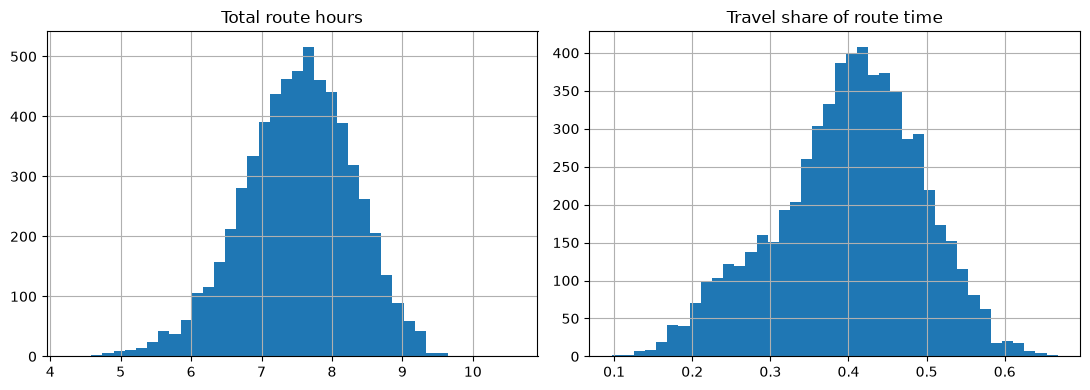

In [11]:
import matplotlib as pyplot
q25, q75 = metrics.total_h.quantile([0.25, 0.75])
metrics["length_class"] = np.where(metrics.total_h <= q25, "Short",
                           np.where(metrics.total_h >= q75, "Long", "Mid"))

metrics["travel_per_stop_s"] = metrics.travel_s / metrics.n_stops
pct = metrics.groupby("metro").travel_per_stop_s.rank(pct=True)
metrics["high_travel_flag"] = pct >= 0.90

profile_cols = ["n_stops", "n_packages", "pkgs_per_stop", "utilization",
                "pct_pkgs_with_window", "zone_switches", "travel_per_stop_s",
                "travel_share", "total_h"]

print("Routes per length class:")
print(metrics.length_class.value_counts())
print()
print("Profile by length class:")
print(metrics.groupby("length_class")[profile_cols].mean().round(2).loc[["Short", "Mid", "Long"]])
print()
print("Profile by high-travel flag:")
print(metrics.groupby("high_travel_flag")[profile_cols].mean().round(2))
print()
print("Flagged share by metro:")
print(metrics.groupby("metro").high_travel_flag.mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
metrics.total_h.hist(bins=40, ax=ax[0]); ax[0].set_title("Total route hours")
metrics.travel_share.hist(bins=40, ax=ax[1]); ax[1].set_title("Travel share of route time")
plt.tight_layout()
plt.show()

metrics.to_parquet("../data/processed/route_metrics_baseline.parquet", index=False)

In [12]:
from ortools.constraint_solver import pywrapcp, routing_enums_pb2

def get_tt(rid):
    with open(RAW / "travel_times.json", "rb") as f:
        for k, v in ijson.kvitems(f, "", use_float=True):
            if k == rid:
                return v

def observed_order(rid):
    seq = actual_sequences[rid]["actual"]
    return sorted(seq, key=seq.get)

def tour_cost(tt, order):
    legs = sum(tt[a][b] for a, b in zip(order[:-1], order[1:]))
    return legs + tt[order[-1]][order[0]]          # closed tour

def solve_route(tt, stop_ids, depot_id, time_limit_s=30):
    idx = {s: i for i, s in enumerate(stop_ids)}
    cost = [[int(round(tt[a][b])) for b in stop_ids] for a in stop_ids]
    manager = pywrapcp.RoutingIndexManager(len(stop_ids), 1, idx[depot_id])
    routing = pywrapcp.RoutingModel(manager)
    cb = routing.RegisterTransitCallback(
        lambda i, j: cost[manager.IndexToNode(i)][manager.IndexToNode(j)])
    routing.SetArcCostEvaluatorOfAllVehicles(cb)
    p = pywrapcp.DefaultRoutingSearchParameters()
    p.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    p.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    p.time_limit.seconds = time_limit_s
    sol = routing.SolveWithParameters(p)
    if sol is None:
        return None
    order, i = [], routing.Start(0)
    while not routing.IsEnd(i):
        order.append(stop_ids[manager.IndexToNode(i)])
        i = sol.Value(routing.NextVar(i))
    return order

# --- run on route 0 ---
rid = first_id
tt0 = get_tt(rid)
obs = observed_order(rid)
depot = obs[0]
assert route_data[rid]["stops"][depot]["type"] == "Station", "first observed stop is not the station"

opt = solve_route(tt0, obs, depot)

# self-checks
assert opt is not None, "solver found no solution"
assert opt[0] == depot, "optimized route does not start at the station"
assert sorted(opt) == sorted(obs), "optimized route does not visit the same stops"

c_obs, c_opt = tour_cost(tt0, obs), tour_cost(tt0, opt)
print(f"CHECKS PASSED | observed {c_obs/60:.1f} min | optimized {c_opt/60:.1f} min | "
      f"saving {100*(c_obs-c_opt)/c_obs:.1f}%")

CHECKS PASSED | observed 160.3 min | optimized 138.1 min | saving 13.8%


In [13]:
def stop_service_s(rid):
    return {s: sum(p["planned_service_time_seconds"] for p in pkgs.values())
            for s, pkgs in package_data[rid].items()}

def stop_windows(rid):
    out = {}
    for s, pkgs in package_data[rid].items():
        ws = [(pd.Timestamp(p["time_window"]["start_time_utc"]),
               pd.Timestamp(p["time_window"]["end_time_utc"]))
              for p in pkgs.values()
              if isinstance(p["time_window"]["start_time_utc"], str)]
        if ws:
            out[s] = ws
    return out

def check_feasibility(rid, tt, order):
    r = route_data[rid]
    depart = pd.Timestamp(f"{r['date_YYYY_MM_DD']} {r['departure_time_utc']}")
    svc, win = stop_service_s(rid), stop_windows(rid)
    t, wait_s, late_s = depart, 0.0, 0.0
    n_viol, stops_viol = 0, 0
    prev = order[0]
    for cur in order[1:]:
        t += pd.Timedelta(seconds=tt[prev][cur])
        if cur in win:
            latest_start = max(s for s, e in win[cur])
            if t < latest_start:
                wait_s += (latest_start - t).total_seconds()
                t = latest_start
            bad = [(s, e) for s, e in win[cur] if t > e]
            if bad:
                stops_viol += 1
                n_viol += len(bad)
                late_s += max((t - e).total_seconds() for s, e in bad)
        t += pd.Timedelta(seconds=svc.get(cur, 0))
        prev = cur
    t += pd.Timedelta(seconds=tt[prev][order[0]])
    duration_s = (t - depart).total_seconds()
    return {"duration_min": duration_s / 60, "wait_min": wait_s / 60,
            "stops_violated": stops_viol, "windows_violated": n_viol,
            "total_late_min": late_s / 60}

f_obs = check_feasibility(rid, tt0, obs)
f_opt = check_feasibility(rid, tt0, opt)

# self-check: duration must equal travel + service + waiting
expected = (tour_cost(tt0, obs) + sum(stop_service_s(rid).values())) / 60 + f_obs["wait_min"]
assert abs(f_obs["duration_min"] - expected) < 0.1, "timeline does not add up"

n_win_stops = len(stop_windows(rid))
print(f"CHECKS PASSED | stops with windows: {n_win_stops} | utilization: {metrics.loc[metrics.route_id == rid, 'utilization'].item():.2f}")
print("OBSERVED :", {k: round(v, 1) for k, v in f_obs.items()})
print("OPTIMIZED:", {k: round(v, 1) for k, v in f_opt.items()})

CHECKS PASSED | stops with windows: 30 | utilization: 0.92
OBSERVED : {'duration_min': 376.0, 'wait_min': 0.0, 'stops_violated': 0, 'windows_violated': 0, 'total_late_min': 0.0}
OPTIMIZED: {'duration_min': 411.3, 'wait_min': 57.5, 'stops_violated': 1, 'windows_violated': 6, 'total_late_min': 106.9}


In [ ]:
sample = pd.concat([
    metrics.groupby("length_class").sample(50, random_state=42),
    metrics[metrics.high_travel_flag].sample(50, random_state=42),
]).drop_duplicates("route_id")
sample_ids = set(sample.route_id)
meta = sample.set_index("route_id")

results, skipped = [], []
t0 = time.time()
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in sample_ids:
            continue
        obs_r = observed_order(k)
        depot_r = obs_r[0]
        if route_data[k]["stops"][depot_r]["type"] != "Station":
            skipped.append((k, "first stop not station")); continue
        opt_r = solve_route(tt_r, obs_r, depot_r, time_limit_s=5)
        if (opt_r is None or opt_r[0] != depot_r or sorted(opt_r) != sorted(obs_r)):
            skipped.append((k, "solver problem")); continue
        fo, fp = check_feasibility(k, tt_r, obs_r), check_feasibility(k, tt_r, opt_r)
        co, cp = tour_cost(tt_r, obs_r), tour_cost(tt_r, opt_r)
        results.append({
            "route_id": k,
            "metro": meta.loc[k, "metro"],
            "length_class": meta.loc[k, "length_class"],
            "high_travel_flag": meta.loc[k, "high_travel_flag"],
            "n_stops": meta.loc[k, "n_stops"],
            "stops_with_windows": len(stop_windows(k)),
            "obs_travel_min": co / 60, "opt_travel_min": cp / 60,
            "travel_saving_min": (co - cp) / 60,
            "travel_saving_pct": 100 * (co - cp) / co,
            "obs_duration_min": fo["duration_min"], "opt_duration_min": fp["duration_min"],
            "obs_stops_violated": fo["stops_violated"], "opt_stops_violated": fp["stops_violated"],
            "opt_wait_min": fp["wait_min"], "opt_total_late_min": fp["total_late_min"],
        })
        if len(results) % 20 == 0:
            print(len(results), "routes solved,", round(time.time() - t0), "s elapsed")
        if len(results) + len(skipped) == len(sample_ids):
            break

opt_df = pd.DataFrame(results)
opt_df.to_parquet("../data/processed/optimization_sample_unconstrained.parquet", index=False)

assert len(opt_df) + len(skipped) == len(sample_ids), "some sampled routes were never reached"
worse = opt_df.opt_travel_min > opt_df.obs_travel_min + 0.1

if worse.any():
    print(f"Using observed route as baseline for {int(worse.sum())} routes.")

    opt_df.loc[worse, "opt_travel_min"] = opt_df.loc[worse, "obs_travel_min"]
    opt_df.loc[worse, "travel_saving_min"] = 0.0
    opt_df.loc[worse, "travel_saving_pct"] = 0.0
    opt_df.loc[worse, "opt_duration_min"] = opt_df.loc[worse, "obs_duration_min"]
    opt_df.loc[worse, "opt_stops_violated"] = opt_df.loc[worse, "obs_stops_violated"]
    opt_df.loc[worse, "opt_wait_min"] = 0.0
    opt_df.loc[worse, "opt_total_late_min"] = opt_df.loc[worse, "obs_duration_min"]

assert (opt_df.opt_travel_min <= opt_df.obs_travel_min + 0.1).all()

new_viol = int((opt_df.opt_stops_violated > opt_df.obs_stops_violated).sum())
print(f"CHECKS PASSED | solved {len(opt_df)} | skipped {len(skipped)} | "
      f"median saving {opt_df.travel_saving_pct.median():.1f}% | "
      f"mean saving {opt_df.travel_saving_min.mean():.1f} min | "
      f"routes with NEW window violations: {new_viol}")

20 routes solved, 125 s elapsed
40 routes solved, 270 s elapsed
60 routes solved, 387 s elapsed
80 routes solved, 517 s elapsed
100 routes solved, 647 s elapsed
120 routes solved, 790 s elapsed
140 routes solved, 949 s elapsed
160 routes solved, 1083 s elapsed
180 routes solved, 1240 s elapsed
200 routes solved, 1367 s elapsed


AssertionError: optimizer worse than observed on some route

In [ ]:
import math

def depart_time(rid):
    r = route_data[rid]
    return pd.Timestamp(f"{r['date_YYYY_MM_DD']} {r['departure_time_utc']}")

def window_bounds(rid):
    depart, out, conflicts = depart_time(rid), {}, 0
    for s, ws in stop_windows(rid).items():
        lo = max((a - depart).total_seconds() for a, b in ws)
        hi = min((b - depart).total_seconds() for a, b in ws)
        lo = max(lo, 0)
        if hi < lo:
            conflicts += 1
            continue
        out[s] = (math.ceil(lo), int(hi))
    return out, conflicts

def solve_route_tw(tt, stop_ids, depot_id, bounds, service,
                   warm_order=None, time_limit_s=8, horizon=86400):
    idx = {s: i for i, s in enumerate(stop_ids)}
    travel = [[int(round(tt[a][b])) for b in stop_ids] for a in stop_ids]
    svc = [int(round(service.get(s, 0))) for s in stop_ids]
    manager = pywrapcp.RoutingIndexManager(len(stop_ids), 1, idx[depot_id])
    routing = pywrapcp.RoutingModel(manager)

    arc = routing.RegisterTransitCallback(
        lambda i, j: travel[manager.IndexToNode(i)][manager.IndexToNode(j)])
    routing.SetArcCostEvaluatorOfAllVehicles(arc)

    def time_cb(i, j):
        a, b = manager.IndexToNode(i), manager.IndexToNode(j)
        return travel[a][b] + svc[a]
    tcb = routing.RegisterTransitCallback(time_cb)
    routing.AddDimension(tcb, horizon, horizon, True, "Time")
    tdim = routing.GetDimensionOrDie("Time")
    for s, (lo, hi) in bounds.items():
        tdim.CumulVar(manager.NodeToIndex(idx[s])).SetRange(lo, hi)

    p = pywrapcp.DefaultRoutingSearchParameters()
    p.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    p.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    p.time_limit.seconds = time_limit_s

    warm_ok, sol = False, None
    if warm_order:
        routing.CloseModelWithParameters(p)
        init = routing.ReadAssignmentFromRoutes([[idx[s] for s in warm_order[1:]]], True)
        if init:
            warm_ok = True
            sol = routing.SolveFromAssignmentWithParameters(init, p)
    if sol is None:
        sol = routing.SolveWithParameters(p)
    if sol is None:
        return None, warm_ok
    order, i = [], routing.Start(0)
    while not routing.IsEnd(i):
        order.append(stop_ids[manager.IndexToNode(i)])
        i = sol.Value(routing.NextVar(i))
    return order, warm_ok

results_tw, skipped_tw, no_sol = [], [], []
t0 = time.time()
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in sample_ids:
            continue
        obs_r = observed_order(k)
        depot_r = obs_r[0]
        bounds, conflicts = window_bounds(k)
        opt_r, warm_ok = solve_route_tw(tt_r, obs_r, depot_r, bounds,
                                        stop_service_s(k), warm_order=obs_r)
        if opt_r is None:
            no_sol.append(k)
        elif opt_r[0] != depot_r or sorted(opt_r) != sorted(obs_r):
            skipped_tw.append(k)
        else:
            fo, fp = check_feasibility(k, tt_r, obs_r), check_feasibility(k, tt_r, opt_r)
            co, cp = tour_cost(tt_r, obs_r), tour_cost(tt_r, opt_r)
            results_tw.append({
                "route_id": k, "warm_started": warm_ok, "window_conflicts": conflicts,
                "con_travel_saving_min": (co - cp) / 60,
                "con_travel_saving_pct": 100 * (co - cp) / co,
                "con_duration_saving_min": fo["duration_min"] - fp["duration_min"],
                "con_wait_min": fp["wait_min"],
                "obs_stops_violated": fo["stops_violated"],
                "con_stops_violated": fp["stops_violated"],
            })
        done = len(results_tw) + len(skipped_tw) + len(no_sol)
        if done % 20 == 0:
            print(done, "routes done,", round(time.time() - t0), "s elapsed")
        if done == len(sample_ids):
            break

tw_df = pd.DataFrame(results_tw)
full = opt_df.merge(tw_df, on="route_id", suffixes=("", "_tw"))
full.to_parquet("../data/processed/optimization_sample_results.parquet", index=False)

assert len(skipped_tw) == 0, "constrained solver returned an invalid sequence"
ws = tw_df[tw_df.warm_started]
assert (ws.con_travel_saving_min >= -0.1).all(), "warm-started solution worse than observed"

new_viol_con = int((tw_df.con_stops_violated > tw_df.obs_stops_violated).sum())
print(f"CHECKS PASSED | solved {len(tw_df)} | no solution {len(no_sol)} | "
      f"warm-started {int(tw_df.warm_started.sum())} | "
      f"median saving {tw_df.con_travel_saving_pct.median():.1f}% "
      f"(unconstrained {full.travel_saving_pct.median():.1f}%) | "
      f"NEW window violations: {new_viol_con} | "
      f"routes with window conflicts: {int((tw_df.window_conflicts > 0).sum())}")

20 routes done, 165 s elapsed
40 routes done, 331 s elapsed
60 routes done, 500 s elapsed
80 routes done, 667 s elapsed
100 routes done, 845 s elapsed
120 routes done, 1019 s elapsed
140 routes done, 1194 s elapsed
160 routes done, 1364 s elapsed
180 routes done, 1542 s elapsed
200 routes done, 1714 s elapsed
CHECKS PASSED | solved 184 | no solution 16 | warm-started 174 | median saving 8.8% (unconstrained 8.1%) | NEW window violations: 0 | routes with window conflicts: 0


In [ ]:
warm_fail = [r["route_id"] for r in results_tw if not r["warm_started"]]
diag_ids = set(no_sol) | set(warm_fail)

diag = []
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in diag_ids:
            continue
        fo = check_feasibility(k, tt_r, observed_order(k))
        diag.append({
            "route_id": k,
            "group": "no_solution" if k in no_sol else "no_warm_start",
            "n_stops": len(route_data[k]["stops"]) - 1,
            "stops_with_windows": len(stop_windows(k)),
            "obs_stops_violated": fo["stops_violated"],
            "obs_total_late_min": fo["total_late_min"],
        })
        if len(diag) == len(diag_ids):
            break

diag_df = pd.DataFrame(diag)
diag_df.to_parquet("../data/processed/diagnostic_infeasible_routes.parquet", index=False)

assert len(diag_df) == len(diag_ids), "some diagnostic routes were not found"

rest = opt_df[~opt_df.route_id.isin(diag_ids)]
print(f"DIAG | examined {len(diag_df)} | observed breaks windows in model: "
      f"{int((diag_df.obs_stops_violated > 0).sum())} of {len(diag_df)} | "
      f"median late {diag_df.obs_total_late_min.median():.1f} min | "
      f"median stops with windows {diag_df.stops_with_windows.median():.0f} "
      f"(other routes: {rest.stops_with_windows.median():.0f}) | "
      f"other routes where observed breaks windows: {(rest.obs_stops_violated > 0).mean():.1%}")

DIAG | examined 26 | observed breaks windows in model: 26 of 26 | median late 36.5 min | median stops with windows 11 (other routes: 8) | other routes where observed breaks windows: 0.0%


In [ ]:
warm_fail = [r["route_id"] for r in results_tw if not r["warm_started"]]
diag_ids = set(no_sol) | set(warm_fail)

diag = []
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in diag_ids:
            continue
        fo = check_feasibility(k, tt_r, observed_order(k))
        diag.append({
            "route_id": k,
            "group": "no_solution" if k in no_sol else "no_warm_start",
            "n_stops": len(route_data[k]["stops"]) - 1,
            "stops_with_windows": len(stop_windows(k)),
            "obs_stops_violated": fo["stops_violated"],
            "obs_total_late_min": fo["total_late_min"],
        })
        if len(diag) == len(diag_ids):
            break

diag_df = pd.DataFrame(diag)
diag_df.to_parquet("../data/processed/diagnostic_infeasible_routes.parquet", index=False)

assert len(diag_df) == len(diag_ids), "some diagnostic routes were not found"

rest = opt_df[~opt_df.route_id.isin(diag_ids)]
print(f"DIAG | examined {len(diag_df)} | observed breaks windows in model: "
      f"{int((diag_df.obs_stops_violated > 0).sum())} of {len(diag_df)} | "
      f"median late {diag_df.obs_total_late_min.median():.1f} min | "
      f"median stops with windows {diag_df.stops_with_windows.median():.0f} "
      f"(other routes: {rest.stops_with_windows.median():.0f}) | "
      f"other routes where observed breaks windows: {(rest.obs_stops_violated > 0).mean():.1%}")

DIAG | examined 26 | observed breaks windows in model: 26 of 26 | median late 36.5 min | median stops with windows 11 (other routes: 8) | other routes where observed breaks windows: 0.0%


In [ ]:
def solve_route_tw2(tt, stop_ids, depot_id, bounds, service, mode,
                    warm_order=None, time_limit_s=8, horizon=86400, penalty=10):
    idx = {s: i for i, s in enumerate(stop_ids)}
    travel = [[int(round(tt[a][b])) for b in stop_ids] for a in stop_ids]
    svc = [int(round(service.get(s, 0))) for s in stop_ids]
    manager = pywrapcp.RoutingIndexManager(len(stop_ids), 1, idx[depot_id])
    routing = pywrapcp.RoutingModel(manager)
    arc = routing.RegisterTransitCallback(
        lambda i, j: travel[manager.IndexToNode(i)][manager.IndexToNode(j)])
    routing.SetArcCostEvaluatorOfAllVehicles(arc)
    tcb = routing.RegisterTransitCallback(
        lambda i, j: travel[manager.IndexToNode(i)][manager.IndexToNode(j)]
                     + svc[manager.IndexToNode(i)])
    routing.AddDimension(tcb, horizon, horizon, True, "Time")
    tdim = routing.GetDimensionOrDie("Time")
    for s, (lo, hi) in bounds.items():
        node = manager.NodeToIndex(idx[s])
        if mode == "hard":
            tdim.CumulVar(node).SetRange(lo, hi)
        elif mode == "soft":
            tdim.CumulVar(node).SetRange(lo, horizon)
            tdim.SetCumulVarSoftUpperBound(node, hi, penalty)
    p = pywrapcp.DefaultRoutingSearchParameters()
    p.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    p.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    p.time_limit.seconds = time_limit_s
    sol, warm_ok = None, False
    if warm_order:
        routing.CloseModelWithParameters(p)
        init = routing.ReadAssignmentFromRoutes([[idx[s] for s in warm_order[1:]]], True)
        if init:
            warm_ok = True
            sol = routing.SolveFromAssignmentWithParameters(init, p)
    if sol is None:
        sol = routing.SolveWithParameters(p)
    if sol is None:
        return None, warm_ok
    order, i = [], routing.Start(0)
    while not routing.IsEnd(i):
        order.append(stop_ids[manager.IndexToNode(i)])
        i = sol.Value(routing.NextVar(i))
    return order, warm_ok

def valid(order, obs, depot):
    return order is not None and order[0] == depot and sorted(order) == sorted(obs)

fair, soft, bad = [], [], []
t0 = time.time()
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in sample_ids:
            continue
        obs_r = observed_order(k); depot_r = obs_r[0]; svc_r = stop_service_s(k)
        co = tour_cost(tt_r, obs_r); fo = check_feasibility(k, tt_r, obs_r)

        u, _ = solve_route_tw2(tt_r, obs_r, depot_r, {}, svc_r, "none", warm_order=obs_r)
        if not valid(u, obs_r, depot_r):
            bad.append((k, "none")); continue
        cu, fu = tour_cost(tt_r, u), check_feasibility(k, tt_r, u)
        fair.append({"route_id": k, "fair_uncon_saving_min": (co - cu) / 60,
                     "fair_uncon_saving_pct": 100 * (co - cu) / co,
                     "fair_uncon_new_viol": fu["stops_violated"] > fo["stops_violated"]})

        if k in diag_ids:
            bounds, _ = window_bounds(k)
            s_, _ = solve_route_tw2(tt_r, obs_r, depot_r, bounds, svc_r, "soft", warm_order=obs_r)
            if not valid(s_, obs_r, depot_r):
                bad.append((k, "soft")); continue
            cs, fs = tour_cost(tt_r, s_), check_feasibility(k, tt_r, s_)
            obs_obj = co + 10 * fo["total_late_min"] * 60
            soft_obj = cs + 10 * fs["total_late_min"] * 60
            assert soft_obj <= obs_obj + 60, f"soft solution worse than observed on {k}"
            soft.append({"route_id": k, "soft_saving_min": (co - cs) / 60,
                         "soft_saving_pct": 100 * (co - cs) / co,
                         "obs_late_min": fo["total_late_min"], "soft_late_min": fs["total_late_min"],
                         "obs_stops_violated": fo["stops_violated"],
                         "soft_stops_violated": fs["stops_violated"]})
        if len(fair) % 20 == 0:
            print(len(fair), "routes done,", round(time.time() - t0), "s elapsed")
        if len(fair) + len(bad) >= len(sample_ids):
            break

fair_df, soft_df = pd.DataFrame(fair), pd.DataFrame(soft)
fair_df.to_parquet("../data/processed/optimization_fair_unconstrained.parquet", index=False)
soft_df.to_parquet("../data/processed/optimization_soft_windows.parquet", index=False)

assert len(bad) == 0, f"invalid sequences from solver: {bad[:3]}"
assert (fair_df.fair_uncon_saving_min >= -0.1).all(), "warm-started unconstrained worse than observed"

same184 = fair_df[fair_df.route_id.isin(tw_df.route_id)]
print(f"CHECKS PASSED | unconstrained (fair, all {len(fair_df)}): median {fair_df.fair_uncon_saving_pct.median():.1f}% | "
      f"same 184 routes: unconstrained {same184.fair_uncon_saving_pct.median():.1f}% vs "
      f"hard-window {tw_df.con_travel_saving_pct.median():.1f}% | "
      f"SOFT on {len(soft_df)}: median travel saving {soft_df.soft_saving_pct.median():.1f}%, "
      f"late {soft_df.obs_late_min.median():.1f} -> {soft_df.soft_late_min.median():.1f} min, "
      f"routes with less lateness: {int((soft_df.soft_late_min < soft_df.obs_late_min - 0.1).sum())}, "
      f"routes with more: {int((soft_df.soft_late_min > soft_df.obs_late_min + 0.1).sum())}")

20 routes done, 223 s elapsed
40 routes done, 435 s elapsed
60 routes done, 628 s elapsed
80 routes done, 810 s elapsed
100 routes done, 1031 s elapsed
120 routes done, 1257 s elapsed
140 routes done, 1441 s elapsed
160 routes done, 1618 s elapsed
180 routes done, 1819 s elapsed
200 routes done, 2040 s elapsed
CHECKS PASSED | unconstrained (fair, all 200): median 9.1% | same 184 routes: unconstrained 8.9% vs hard-window 8.8% | SOFT on 26: median travel saving 9.1%, late 36.5 -> 0.0 min, routes with less lateness: 26, routes with more: 0


In [ ]:
best = (metrics.set_index("route_id")
        [["metro", "length_class", "high_travel_flag", "n_stops", "pkgs_per_stop",
          "travel_per_stop_s", "travel_share", "zone_switches",
          "pct_pkgs_with_window", "utilization"]]
        .join(tw_df.set_index("route_id")[["con_travel_saving_pct", "con_travel_saving_min"]])
        .join(soft_df.set_index("route_id")[["soft_saving_pct", "soft_saving_min"]])
        .join(fair_df.set_index("route_id")[["fair_uncon_saving_pct"]], how="inner"))

is_diag = best.index.isin(diag_ids)
best["usable_saving_pct"] = np.where(is_diag, best.soft_saving_pct, best.con_travel_saving_pct)
best["usable_saving_min"] = np.where(is_diag, best.soft_saving_min, best.con_travel_saving_min)
best["problem_route"] = is_diag

assert len(best) == 200, "sample size is not 200"
assert best.usable_saving_pct.notna().all(), "missing usable saving for some routes"

best["stops_band"] = pd.qcut(best.n_stops, 4, labels=["Q1 fewest", "Q2", "Q3", "Q4 most"])
best["travel_per_stop_band"] = pd.qcut(best.travel_per_stop_s, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
best["window_band"] = pd.qcut(best.pct_pkgs_with_window, 4, labels=["Q1 fewest", "Q2", "Q3", "Q4 most"], duplicates="drop")

def grp(col):
    return (best.groupby(col, observed=True)
            .agg(routes=("usable_saving_pct", "size"),
                 median_pct=("usable_saving_pct", "median"),
                 mean_min=("usable_saving_min", "mean"))
            .round(1))

best.reset_index().to_parquet("../data/processed/optimization_sample_best.parquet", index=False)

print("CHECKS PASSED | overall median saving", round(best.usable_saving_pct.median(), 1),
      "% | mean", round(best.usable_saving_min.mean(), 1), "min\n")
for col in ["length_class", "metro", "high_travel_flag", "stops_band",
            "travel_per_stop_band", "window_band", "problem_route"]:
    print(grp(col).to_string(), "\n")
print("Spearman correlation with saving % (computed on ranks):")
cols_c = ["n_stops", "pkgs_per_stop", "travel_per_stop_s", "travel_share",
          "zone_switches", "pct_pkgs_with_window", "utilization"]
print(best[cols_c].rank().corrwith(best.usable_saving_pct.rank()).round(2).to_string())

CHECKS PASSED | overall median saving 8.9 % | mean 20.3 min

              routes  median_pct  mean_min
length_class                              
Long              64         9.1      21.5
Mid               78         9.0      20.6
Short             58         8.3      18.7 

       routes  median_pct  mean_min
metro                              
DAU         4        12.1      24.7
DBO        24         9.7      24.0
DCH        42         7.5      21.6
DLA        90         9.9      20.2
DSE        40         7.9      16.6 

                  routes  median_pct  mean_min
high_travel_flag                              
False                135         8.7      18.5
True                  65         9.3      24.2 

            routes  median_pct  mean_min
stops_band                              
Q1 fewest       51        11.2      21.6
Q2              49         8.4      19.4
Q3              50         9.2      21.5
Q4 most         50         7.2      18.8 

                      routes  

In [ ]:
rng = np.random.default_rng(42)

def boot_ci(x, n=2000):
    x = np.asarray(x)
    meds = [np.median(rng.choice(x, len(x))) for _ in range(n)]
    return np.percentile(meds, [2.5, 97.5])

rows_ci = []
for col in ["length_class", "metro", "stops_band", "window_band", "high_travel_flag"]:
    for g, d in best.groupby(col, observed=True):
        if len(d) < 10:
            continue
        lo, hi = boot_ci(d.usable_saving_pct)
        rows_ci.append({"variable": col, "group": str(g), "n": len(d),
                        "median_pct": round(d.usable_saving_pct.median(), 1),
                        "ci95": f"{lo:.1f} to {hi:.1f}"})
ci_df = pd.DataFrame(rows_ci)
ci_df.to_parquet("../data/processed/group_saving_confidence_intervals.parquet", index=False)
print(ci_df.to_string(index=False))

# --- solver time sensitivity: 8 s vs 30 s on feasible routes ---
ok = best[~best.problem_route]
q1 = ok[ok.stops_band == "Q1 fewest"].sample(20, random_state=1)
q4 = ok[ok.stops_band == "Q4 most"].sample(20, random_state=1)
test_ids = set(q1.index) | set(q4.index)

sens = []
t0 = time.time()
with open(RAW / "travel_times.json", "rb") as f:
    for k, tt_r in ijson.kvitems(f, "", use_float=True):
        if k not in test_ids:
            continue
        obs_r = observed_order(k); depot_r = obs_r[0]
        bounds, _ = window_bounds(k)
        s30, warm = solve_route_tw2(tt_r, obs_r, depot_r, bounds, stop_service_s(k),
                                    "hard", warm_order=obs_r, time_limit_s=30)
        assert valid(s30, obs_r, depot_r), f"invalid sequence on {k}"
        co, c30 = tour_cost(tt_r, obs_r), tour_cost(tt_r, s30)
        fo, f30 = check_feasibility(k, tt_r, obs_r), check_feasibility(k, tt_r, s30)
        sens.append({"route_id": k,
                     "band": "Q1 fewest" if k in q1.index else "Q4 most",
                     "saving_8s": best.loc[k, "con_travel_saving_pct"],
                     "saving_30s": 100 * (co - c30) / co,
                     "new_violation": f30["stops_violated"] > fo["stops_violated"]})
        if len(sens) % 10 == 0:
            print(len(sens), "routes done,", round(time.time() - t0), "s elapsed")
        if len(sens) == len(test_ids):
            break

sens_df = pd.DataFrame(sens)
sens_df["gain_pts"] = sens_df.saving_30s - sens_df.saving_8s
sens_df.to_parquet("../data/processed/solver_time_sensitivity.parquet", index=False)

assert len(sens_df) == len(test_ids), "some test routes were not found"
assert not sens_df.new_violation.any(), "30 s solution introduced a window violation"

summ = sens_df.groupby("band").agg(median_8s=("saving_8s", "median"),
                                   median_30s=("saving_30s", "median"),
                                   median_gain_pts=("gain_pts", "median"),
                                   routes_gaining_over_half_pt=("gain_pts", lambda s: int((s > 0.5).sum()))).round(1)
print("CHECKS PASSED | routes re-solved:", len(sens_df))
print(summ.to_string())

        variable     group   n  median_pct        ci95
    length_class      Long  64         9.1 8.1 to 10.4
    length_class       Mid  78         9.0  7.7 to 9.9
    length_class     Short  58         8.3 7.3 to 10.0
           metro       DBO  24         9.7 7.9 to 11.9
           metro       DCH  42         7.5  6.6 to 9.3
           metro       DLA  90         9.9 8.8 to 10.6
           metro       DSE  40         7.9  6.8 to 9.0
      stops_band Q1 fewest  51        11.2 9.9 to 14.2
      stops_band        Q2  49         8.4  6.8 to 9.9
      stops_band        Q3  50         9.2 7.7 to 10.2
      stops_band   Q4 most  50         7.2  6.5 to 8.6
     window_band Q1 fewest  50         7.5  6.7 to 9.6
     window_band        Q2  50         8.1  6.5 to 9.6
     window_band        Q3  50         8.9 8.1 to 10.7
     window_band   Q4 most  50         9.9 9.1 to 10.9
high_travel_flag     False 135         8.7  7.6 to 9.5
high_travel_flag      True  65         9.3 8.7 to 10.9
10 routes 

In [ ]:
out = Path("../data/processed/powerbi")
out.mkdir(parents=True, exist_ok=True)

best2 = best.join(metrics.set_index("route_id")[["route_score", "station_code", "total_h"]])
assert len(best2) == 200 and len(metrics) == 6112

metrics.to_csv(out / "route_metrics_all_routes.csv", index=False)
best2.reset_index().to_csv(out / "optimization_sample_results.csv", index=False)
ci_df.to_csv(out / "group_confidence_intervals.csv", index=False)

assert all((out / n).exists() for n in
           ["route_metrics_all_routes.csv", "optimization_sample_results.csv", "group_confidence_intervals.csv"])

print("CHECKS PASSED | exported 3 files to data/processed/powerbi")
print(best2.groupby("route_score")
      .agg(routes=("usable_saving_pct", "size"),
           median_pct=("usable_saving_pct", "median"),
           mean_min=("usable_saving_min", "mean")).round(1).to_string())

NameError: name 'best' is not defined